# Project 28: Predictive Maintenance Failure Analysis
Notebook ini membaca CSV hasil di `project/results/` (dibuat skrip 01 sampai 10). Data AI4I 2020 (UCI 601) adalah data sintetis; angka dampak berlabel *estimated* dan *simulated*.

In [1]:
from pathlib import Path
import pandas as pd, matplotlib.pyplot as plt
pd.set_option('display.width', 200); pd.set_option('display.max_columns', 30)
RES = next(p for p in (Path('..'), Path('results'), Path('project/results')) if (p / '2-analysis').exists())
R = lambda f: pd.read_csv(next(RES.rglob(f + '.csv')))

## Q13. Kualitas data
Tidak ada sel kosong atau duplikat; ada label yang tidak konsisten (lihat tabel).

In [2]:
dq = R('data_quality'); print(dq.to_string(index=False)); R('label_issues').groupby('masalah').size()

                                        ukuran    nilai
                                         baris  10000.0
                                         kolom     14.0
                                    sel kosong      0.0
                                  udi duplikat      0.0
                           product_id duplikat      0.0
        baris duplikat (semua kolom selain id)      0.0
                                         run L   6000.0
                                         run M   2997.0
                                         run H   1003.0
                           machine_failure = 1    339.0
     machine_failure = 1 tanpa jenis kegagalan      9.0
jenis kegagalan = 1 tetapi machine_failure = 0     18.0
                              di antaranya RNF     18.0
    run dengan lebih dari satu jenis kegagalan     24.0
                        suhu udara minimum (K)    295.3
                       suhu udara maksimum (K)    304.5
                       suhu proses minimum (K)  

masalah
gagal tanpa jenis kegagalan           9
jenis kegagalan tanpa label gagal    18
dtype: int64

## Q1. Failure rate keseluruhan dan per tipe (interval Wilson 95%)

In [3]:
t = R('rate_by_type'); print(t.round(4).to_string(index=False)); R('h2_type_tests').round(5)

 type     n  failures  failures_rate  failures_lo  failures_hi
    L  6000     235.0         0.0392       0.0345       0.0444
    M  2997      83.0         0.0277       0.0224       0.0342
    H  1003      21.0         0.0209       0.0137       0.0318
Semua 10000     339.0         0.0339       0.0305       0.0376


,pasangan,rate_pertama,rate_kedua,rasio,p_fisher,p_bonferroni
0,L vs M,0.03917,0.02769,1.41425,0.00528,0.01584
1,L vs H,0.03917,0.02094,1.87067,0.00347,0.01041
2,M vs H,0.02769,0.02094,1.32274,0.30179,0.90536
3,chi-kuadrat 3 tipe,NaN,NaN,NaN,0.00103,0.00103


## Q2. Jenis kegagalan (Pareto)
Satu run bisa punya lebih dari satu jenis, jadi porsi dihitung dari kejadian jenis.

failure_mode  flags  flags_with_failure  flags_without_failure  share_of_failures  share_of_flags  cum_share
         HDF    115               115.0                    0.0             0.3392          0.3239     0.3239
         OSF     98                98.0                    0.0             0.2891          0.2761     0.6000
         PWF     95                95.0                    0.0             0.2802          0.2676     0.8676
         TWF     46                46.0                    0.0             0.1357          0.1296     0.9972
         RNF     19                 1.0                   18.0             0.0029          0.0028     1.0000


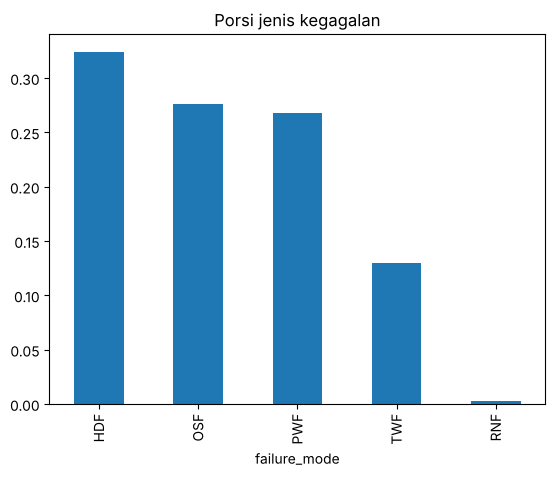

In [4]:
fm = R('failure_modes'); print(fm.round(4).to_string(index=False)); fm.plot.bar(x='failure_mode', y='share_of_flags', legend=False, title='Porsi jenis kegagalan'); plt.show()

## Q3. Tool wear dan titik naiknya risiko (H1)

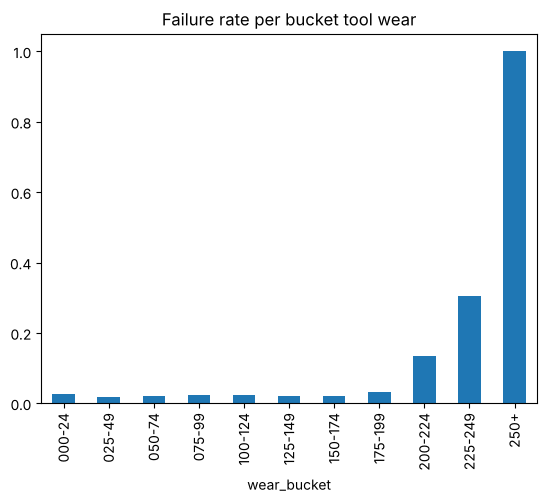

,ambang_menit,n_ge,gagal_ge,rate_ge,n_lt,gagal_lt,rate_lt,rasio,p_fisher,log_likelihood
0,100,5380,236,0.04387,4620,103,0.02229,1.96759,0.00000,18.25688
4,120,4453,211,0.04738,5547,128,0.02308,2.05342,0.00000,22.17845
8,140,3549,197,0.05551,6451,142,0.02201,2.52173,0.00000,37.16033
12,160,2639,176,0.06669,7361,163,0.02214,3.01177,0.00000,51.68842
16,180,1720,155,0.09012,8280,184,0.02222,4.05523,0.00000,77.28547
20,200,801,123,0.15356,9199,216,0.02348,6.53972,0.00000,113.20170
24,220,141,34,0.24113,9859,305,0.03094,7.79458,0.00000,42.23262
28,240,14,4,0.28571,9986,335,0.03355,8.51684,0.00099,5.52553


In [5]:
w = R('wear_bucket'); w.plot.bar(x='wear_bucket', y='failures_rate', legend=False, title='Failure rate per bucket tool wear'); plt.show(); R('h1_wear_scan').round(5).iloc[::4]

## Q4. Torque x rpm (heatmap; sel dengan kurang dari 30 run ditandai tidak andal)

In [6]:
h = R('torque_rpm'); h['rate'] = h.failures_rate.where(h.reliable); print(h.pivot(index='torque_bucket', columns='rpm_bucket', values='rate').round(3))

rpm_bucket     1400-1499  1500-1599  1600-1799  1800+  <1400
torque_bucket                                               
30-39              0.006      0.006      0.005    NaN    NaN
40-49              0.007      0.003        NaN    NaN  0.071
50-59              0.035        NaN        NaN    NaN  0.105
60+                  NaN        NaN        NaN    NaN  0.400
<30                  NaN        NaN      0.007   0.05    NaN


## Q5 sampai Q7. Selisih suhu (HDF), power (PWF), dan tool wear x torque per tipe (OSF)

In [7]:
print(R('temp_diff_hdf').round(4).iloc[:, :8].to_string(index=False)); print(R('power_pwf').round(4).iloc[:, :6].to_string(index=False)); R('h5_type_thresholds')

 diff_bucket    n  hdf  failures  n_rpm_lt_1380  hdf_rpm_lt_1380  hdf_rate  hdf_lo
    a: < 8,0  194 26.0      30.0           26.0             26.0    0.1340  0.0931
  b: 8,0-8,5  526 89.0      96.0           89.0             89.0    0.1692  0.1396
  c: 8,6-9,5 3358  0.0      84.0          443.0              0.0    0.0000  0.0000
 d: 9,6-10,5 2330  0.0      48.0          307.0              0.0    0.0000  0.0000
e: 10,6-11,5 3356  0.0      79.0          471.0              0.0    0.0000  0.0000
  f: >= 11,6  236  0.0       2.0           24.0              0.0    0.0000  0.0000
  power_bucket    n  pwf  failures  pwf_rate  pwf_lo
  a: < 3.500 W   31 31.0      31.0       1.0  0.8897
b: 3.500-4.999 1102  0.0       9.0       0.0  0.0000
c: 5.000-6.499 4686  0.0      39.0       0.0  0.0000
d: 6.500-7.999 3631  0.0     127.0       0.0  0.0000
e: 8.000-9.000  486  0.0      69.0       0.0  0.0000
  f: > 9.000 W   64 64.0      64.0       1.0  0.9434


,type,n,osf,ambang_terbaik_minNm,f1,ambang_boot_p2_5,ambang_boot_p97_5,boot_tanpa_osf
0,L,6000,87,11000,1.0,11000.0,11000.0,0
1,M,2997,9,12000,1.0,12000.0,12000.0,0
2,H,1003,2,12000,1.0,11750.0,12000.0,43


## Hipotesis H1 sampai H5

In [8]:
R('hypotheses')[['id', 'verdict', 'p_value', 'bukti']]

,id,verdict,p_value,bukti
0,H1,Terbukti,3.850667e-51,rate 0.1536 vs 0.0235; ambang terbaik menurut ...
1,H2,Terbukti,1.583653e-02,L vs M p Bonferroni 0.01584; L vs H 0.01041
2,H3,Terbukti,7.152747e-142,rate HDF 0.1777 vs 0.00000; menangkap 100% HDF
3,H4,Terbukti,2.805490e-128,rate PWF di kedua ekor 0.1900 vs 0.00000 di te...
4,H5,Sebagian,7.853341e-118,ambang L/M/H = 11000/12000/12000; interval L d...


## Q8 sampai Q10. Aturan ambang: precision, recall, proporsi peringatan, dibanding baseline

In [9]:
s = R('rule_selection'); s = s[(s.batas_alert_share == 0.10) & (s.period != 'all')]; print(s[['rule_name', 'period', 'precision', 'recall', 'alert_share', 'accuracy']].round(3).to_string(index=False)); R('final_rule_by_type').round(3)

                         rule_name period  precision  recall  alert_share  accuracy
                    tool wear >= T  train      0.146   0.350        0.081     0.909
                    tool wear >= T   test      0.171   0.392        0.078     0.915
                       torque >= T  train      0.248   0.451        0.062     0.935
                       torque >= T   test      0.225   0.412        0.062     0.932
  tool wear >= Tw dan torque >= Tq  train      0.140   0.397        0.096     0.897
  tool wear >= Tw dan torque >= Tq   test      0.163   0.471        0.098     0.900
           tool wear x torque >= P  train      0.204   0.380        0.063     0.929
           tool wear x torque >= P   test      0.221   0.422        0.065     0.930
            power di luar [Pl, Ph]  train      0.190   0.388        0.069     0.923
            power di luar [Pl, Ph]   test      0.166   0.314        0.064     0.923
      selisih suhu < D dan rpm < R  train      0.319   0.435        0.046   

,type,period,n,failures,tp,fp,fn,tn,precision,recall,alert_share,accuracy,f1
0,L,test,1782,67,55,123,12,1592,0.309,0.821,0.100,0.924,0.449
1,L,all,6000,235,186,392,49,5373,0.322,0.791,0.096,0.926,0.458
2,M,test,908,27,20,84,7,797,0.192,0.741,0.115,0.900,0.305
3,M,all,2997,83,58,264,25,2650,0.180,0.699,0.107,0.904,0.286
4,H,test,310,8,6,18,2,284,0.250,0.750,0.077,0.935,0.375
5,H,all,1003,21,14,59,7,923,0.192,0.667,0.073,0.934,0.298


## Q11 dan Q12. Trade-off dan estimasi dampak (estimated, simulated)

In [10]:
print(R('tradeoff').tail(2).to_string(index=False)); i = R('impact'); i[i.skenario == 'titik'][['downtime_per_kegagalan_h', 'porsi_tercegah', 'downtime_terhindari_kotor_h', 'jam_inspeksi_h', 'downtime_terhindari_bersih_h']]

                 rule_name                                                                                  threshold period  failures_caught  failures_missed  false_alerts  alerts  false_alerts_per_caught
aturan terpilih (gabungan) wear x torque: L=11000, M=10500, H=11000 minNm | suhu-rpm: 9.5 K, 1380 rpm | torque: 55 Nm   test               81               21           225     306                   2.7778
aturan terpilih (gabungan) wear x torque: L=11000, M=10500, H=11000 minNm | suhu-rpm: 9.5 K, 1380 rpm | torque: 55 Nm    all              258               81           715     973                   2.7713


,downtime_per_kegagalan_h,porsi_tercegah,downtime_terhindari_kotor_h,jam_inspeksi_h,downtime_terhindari_bersih_h
0,2,0.5,270.0,510.0,-240.0
3,2,0.8,432.0,510.0,-78.0
6,2,1.0,540.0,510.0,30.0
9,4,0.5,540.0,510.0,30.0
12,4,0.8,864.0,510.0,354.0
15,4,1.0,1080.0,510.0,570.0
18,8,0.5,1080.0,510.0,570.0
21,8,0.8,1728.0,510.0,1218.0
24,8,1.0,2160.0,510.0,1650.0


## Q14. Perbandingan dengan dokumentasi UCI dan cek silang

In [11]:
print(R('doc_comparison').to_string(index=False)); print(R('crosscheck_sql_pandas').status.value_counts()); print(R('crosscheck_excel').status.value_counts())

                      komponen                          dokumentasi_uci                                                                                   hasil_data kecocokan
        TWF: rentang tool wear      200 sampai 240 menit (dipilih acak)                                                            198 sampai 253 menit (median 214)    Sesuai
             TWF: jumlah kasus 120 kasus (69 penggantian, 51 kegagalan)                                                                      46 baris dengan TWF = 1   Berbeda
     HDF: selisih suhu dan rpm      selisih suhu < 8.6 K dan rpm < 1380 terbaik di data: selisih suhu < 8.6 K dan rpm < 1380 (F1 1.000); aturan dokumentasi F1 1.000    Sesuai
            PWF: rentang power      di bawah 3500 W atau di atas 9000 W terbaik di data: di bawah 3500 W atau di atas 9000 W (F1 1.000); aturan dokumentasi F1 1.000    Sesuai
OSF tipe L: tool wear x torque                      di atas 11000 minNm                     terbaik di data: 11000 minNm (87 